# ViT Architecture
- - -
![ViT_Architecture](./ViT_Architecture.png)
<!-- <img src="./ViT_Architecture.png" width="100px" height="50px" title="Github_Logo"/> -->

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Layer
import tensorflow_addons as tfa
from tensorflow.keras.optimizers import Adam
from tensorflow_addons.optimizers import AdamW

from tensorflow.distribute import MirroredStrategy,NcclAllReduce
from CodeRepo.load_data import load_data
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

strategy=MirroredStrategy(devices=["GPU:0", "GPU:1"],cross_device_ops=NcclAllReduce(num_packs=2))
data_path='/home/jovyan/data/classification/'

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


In [2]:
num_classes = 2
input_shape = (32, 32, 3)
learning_rate = 0.0001
weight_decay = 0.0001
batch_size = 256
num_epochs = 100
image_size = 32  # We'll resize input images to this size
patch_size = 6  # Size of the patches to be extract from the input images
num_patches = (image_size // patch_size) ** 2
projection_dim = 64
num_heads = 4
transformer_units = [
    projection_dim * 2,
    projection_dim,
]  # Size of the transformer layers
transformer_layers = 2
mlp_head_units = [2048, 1024]  # Size of the dense layers of the final classifier

In [4]:
tr,valid,test=load_data(data_dir_path=data_path,img_size=32,batch_size=256,class_mode='sparse')

Found 544 images belonging to 2 classes.
Found 69 images belonging to 2 classes.
Found 68 images belonging to 2 classes.


In [5]:
tr.image_shape

(32, 32, 3)

In [6]:
def augmentation_layer(img_size,batch_size): ### 사용 안함
    data_augmentation = keras.Sequential(
        [
            layers.experimental.preprocessing.Normalization(),
            layers.experimental.preprocessing.Resizing(image_size, image_size),
            layers.experimental.preprocessing.RandomFlip("horizontal"),
            layers.experimental.preprocessing.RandomRotation(factor=0.02),
            layers.experimental.preprocessing.RandomZoom(height_factor=0.2, width_factor=0.2),
        ],name="data_augmentation",
    )
    # Compute the mean and the variance of the training data for normalization.
    # data_augmentation.layers[0].adapt(x_train)
    data_augmentation.layers[0].adapt((batch_size,img_size,img_size,3))
    
    return data_augmentation

def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

In [7]:
class Patches(layers.Layer):
    def __init__(self, patch_size):
        super(Patches, self).__init__()
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches

In [8]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(4, 4))
# image = x_train[np.random.choice(range(x_train.shape[0]))]
# plt.imshow(image.astype("uint8"))
# plt.axis("off")

# resized_image = tf.image.resize(
#     tf.convert_to_tensor([image]), size=(image_size, image_size)
# )
# patches = Patches(patch_size)(resized_image)
# print(f"Image size: {image_size} X {image_size}")
# print(f"Patch size: {patch_size} X {patch_size}")
# print(f"Patches per image: {patches.shape[1]}")
# print(f"Elements per patch: {patches.shape[-1]}")

# n = int(np.sqrt(patches.shape[1]))
# plt.figure(figsize=(4, 4))
# for i, patch in enumerate(patches[0]):
#     ax = plt.subplot(n, n, i + 1)
#     patch_img = tf.reshape(patch, (patch_size, patch_size, 3))
#     plt.imshow(patch_img.numpy().astype("uint8"))
#     plt.axis("off")

In [9]:
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super(PatchEncoder, self).__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded

In [10]:
def create_vit_classifier():
    inputs = layers.Input(shape=input_shape)
    patches=Patches(patch_size)(inputs)

    # Encode patches.
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)
    transformer_layer_output=[]
    # Create multiple layers of the Transformer block.
    for i in range(transformer_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        # Skip connection 1.
        x2 = layers.Add()([attention_output, encoded_patches])
        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # MLP.
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)
        # Skip connection 2.
        encoded_patches = layers.Add(name='transfotmer_block_out_{}'.format(i))([x3, x2])
        x=mlp(encoded_patches,hidden_units=mlp_head_units,dropout_rate=0.5)
        x=layers.Flatten()(x)
        transformer_layer_output.append(layers.Dense(num_classes)(x))        
    
    # Create a [batch_size, projection_dim] tensor.
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    # Add MLP.
    features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)
    # Classify outputs.
    logits = layers.Dense(num_classes)(features)
    transformer_layer_output.insert(0,logits)
    # Create the Keras model.
    model = keras.Model(inputs=inputs, outputs=transformer_layer_output)
    return model


In [11]:
def run_experiment(set_strategy=False,strategy=None):
    
    # optimizer = tfa.optimizers.AdamW(
    #     learning_rate=learning_rate, weight_decay=weight_decay
    # )
    optimizer=tf.optimizers.Adam(learning_rate=learning_rate)
    if set_strategy:
        with strategy.scope():
            model=create_vit_classifier()
            model.compile(
                optimizer=optimizer,
                loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                metrics=[
                    keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                    # keras.metrics.SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
                ],
            )
    else:
        model=create_vit_classifier()
        model.compile(
                optimizer=optimizer,
                loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                metrics=[
                    keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                    # keras.metrics.SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
                ],
            )

    checkpoint_filepath = "/tmp/checkpoint"
    checkpoint_callback = keras.callbacks.ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
    )


    history=model.fit(
    tr,batch_size=batch_size,
        epochs=num_epochs,
        callbacks=[checkpoint_callback],
        validation_data=valid,
    )

    model.load_weights(checkpoint_filepath)
    _, accuracy, top_5_accuracy = model.evaluate(x_test, y_test)
    print(f"Test accuracy: {round(accuracy * 100, 2)}%")
    print(f"Test top 5 accuracy: {round(top_5_accuracy * 100, 2)}%")

    return history, model

In [12]:
model=create_vit_classifier()

In [13]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 32, 32, 3)]  0                                            
__________________________________________________________________________________________________
patches (Patches)               (None, None, 108)    0           input_1[0][0]                    
__________________________________________________________________________________________________
patch_encoder (PatchEncoder)    (None, 25, 64)       8576        patches[0][0]                    
__________________________________________________________________________________________________
layer_normalization (LayerNorma (None, 25, 64)       128         patch_encoder[0][0]              
______________________________________________________________________________________________

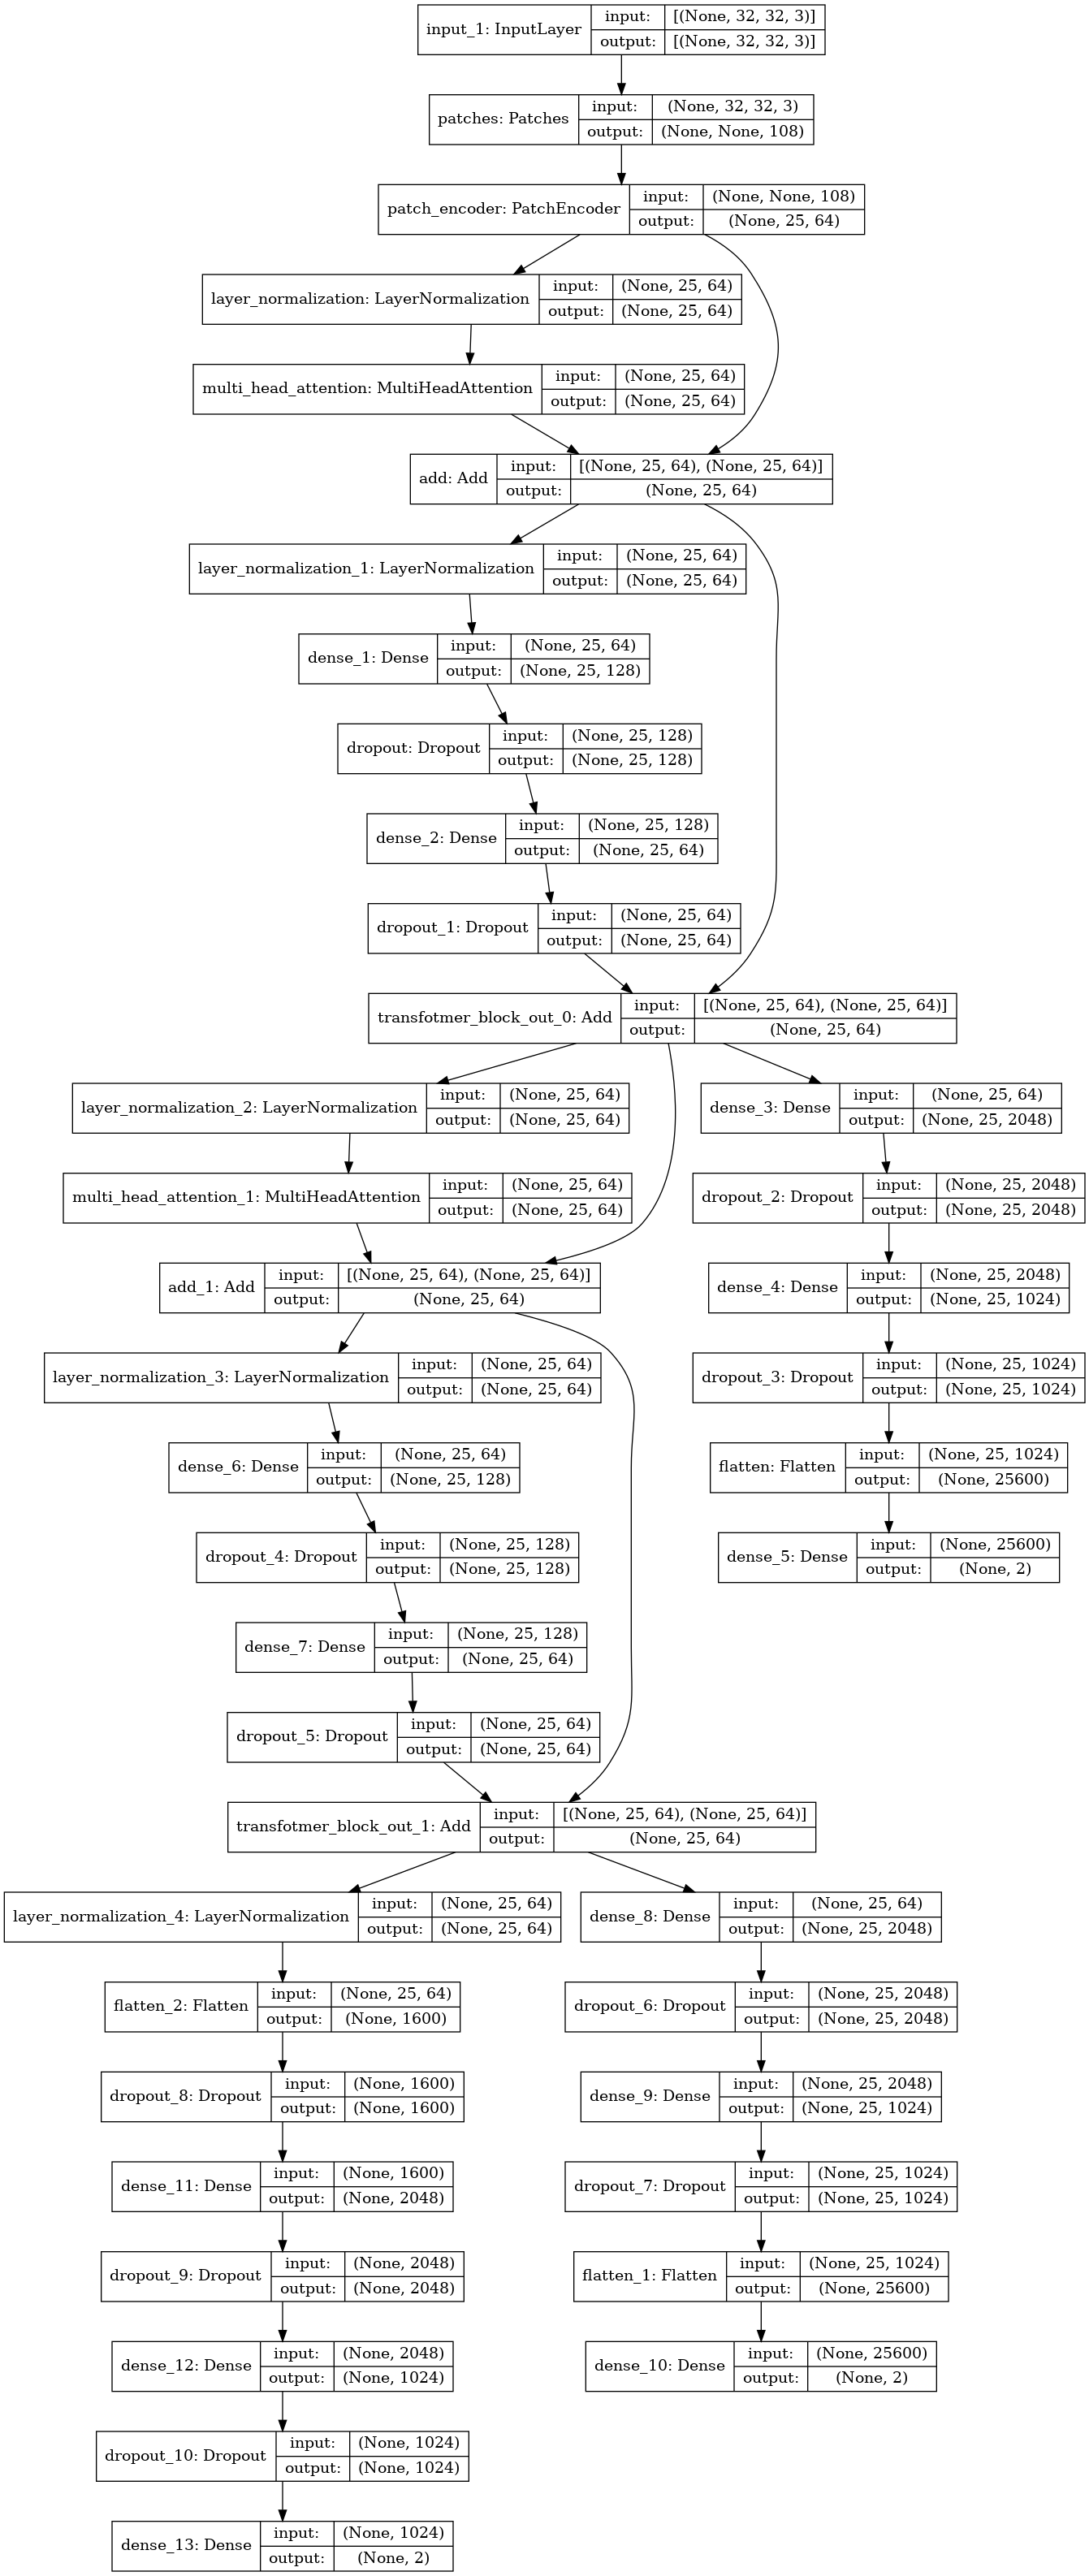

In [14]:
tf.keras.utils.plot_model(
    model,show_shapes=True,
    to_file='model_layer_multiout.png',
    # show_shapes=False,
    # show_dtype=False,
    # show_layer_names=True,
    # rankdir='TB',
    # expand_nested=False,
    dpi=96,
    # layer_range=None,
    # show_layer_activations=False
)